## K-Means Clustering of RL² Hidden States on Evenly Spaced Wind Tasks

This notebook creates the reference hidden states that the other K-Means notebooks in this folder use.

1. **Evenly spaced tasks:** wind torques evenly spaced between −0.5 and +0.5 are created with `sample_tasks_eval`.
2. **Rollout:** the trained RL2 agent plays every task for `steps_per_env` steps with a fixed seed, so the reference run is reproducible. The GRU hidden state of each task is averaged over all steps.
3. **Clustering:** K-Means groups the average hidden states into the k selected in `kmeans_k_selection.ipynb`, with the same settings as in the other notebooks.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import sys
import joblib

from sklearn.decomposition import PCA

sys.path.insert(0, os.path.abspath("../.."))
sys.path.insert(0, os.path.abspath(".."))
from analysis_utils import SYSTEMS, CHECKPOINT_DIR, load_model, collect_avg_hidden_states, task_parameters
from kmeans_utils import CLUSTER_COLORS, fit_kmeans, sort_clusters_by_task_parameter

system = SYSTEMS["pendulum"]

In [2]:
# Generate 20 evenly spaced wind tasks between -0.5 and +0.5
env_configs = system.sample_tasks_eval(num_envs=20)

# Create 20 parallel Pendulum environments based on these configurations
envs = system.make_envs(env_configs)

In [3]:
# Create the RL2 actor-critic model and load the trained weights
model = load_model(system)

In [4]:
steps_per_env = 3000

reference_seed = 42

# Play every task for steps_per_env steps and average its GRU hidden state over all steps
try:
    avg_hidden_states = collect_avg_hidden_states(
        model, system, envs, seed=reference_seed, steps=steps_per_env
    )
finally:
    envs.close()

In [5]:
# Save the 256 dim average hidden states of the evenly spaced tasks
np.save(CHECKPOINT_DIR / "pendulum_wind_avg_hidden_states.npy", avg_hidden_states)

print(avg_hidden_states.shape)

(20, 256)


In [6]:
# Number of clusters selected with the prediction strength in kmeans_k_selection.ipynb
best_k = int(np.load(CHECKPOINT_DIR / "pendulum_wind_kmeans_k_selection.npz")["best_k"])

kmeans = fit_kmeans(avg_hidden_states, best_k)
cluster_assignments = kmeans.labels_

np.save(CHECKPOINT_DIR / "pendulum_wind_cluster_labels.npy", cluster_assignments)
joblib.dump(kmeans, CHECKPOINT_DIR / "pendulum_wind_kmeans.joblib")

print(cluster_assignments)

[1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0]


In [7]:
# Display the wind and assigned cluster for each environment
for i, cfg in enumerate(env_configs):
    print(f"Environment {i}: Wind torque = {cfg['wind_torque']:.3f}, Cluster = {cluster_assignments[i]}")

Environment 0: Wind torque = -0.500, Cluster = 1
Environment 1: Wind torque = -0.447, Cluster = 1
Environment 2: Wind torque = -0.395, Cluster = 1
Environment 3: Wind torque = -0.342, Cluster = 1
Environment 4: Wind torque = -0.289, Cluster = 1
Environment 5: Wind torque = -0.237, Cluster = 1
Environment 6: Wind torque = -0.184, Cluster = 1
Environment 7: Wind torque = -0.132, Cluster = 1
Environment 8: Wind torque = -0.079, Cluster = 1
Environment 9: Wind torque = -0.026, Cluster = 1
Environment 10: Wind torque = 0.026, Cluster = 1
Environment 11: Wind torque = 0.079, Cluster = 0
Environment 12: Wind torque = 0.132, Cluster = 0
Environment 13: Wind torque = 0.184, Cluster = 0
Environment 14: Wind torque = 0.237, Cluster = 0
Environment 15: Wind torque = 0.289, Cluster = 0
Environment 16: Wind torque = 0.342, Cluster = 0
Environment 17: Wind torque = 0.395, Cluster = 0
Environment 18: Wind torque = 0.447, Cluster = 0
Environment 19: Wind torque = 0.500, Cluster = 0


In [8]:
# Reduce the 256 dim average hidden states to 2 dim using PCA
pca = PCA(n_components=2)
reduced_h = pca.fit_transform(avg_hidden_states)

# Save the fitted PCA model
joblib.dump(pca, CHECKPOINT_DIR / "pendulum_wind_pca.joblib")

['C:\\Users\\graph\\OneDrive\\Dokumente\\Uni Wien WS26\\Bachelor Arbeit\\RL2-Torch-Pattern-Recognition\\checkpoints\\pendulum_wind_pca.joblib']

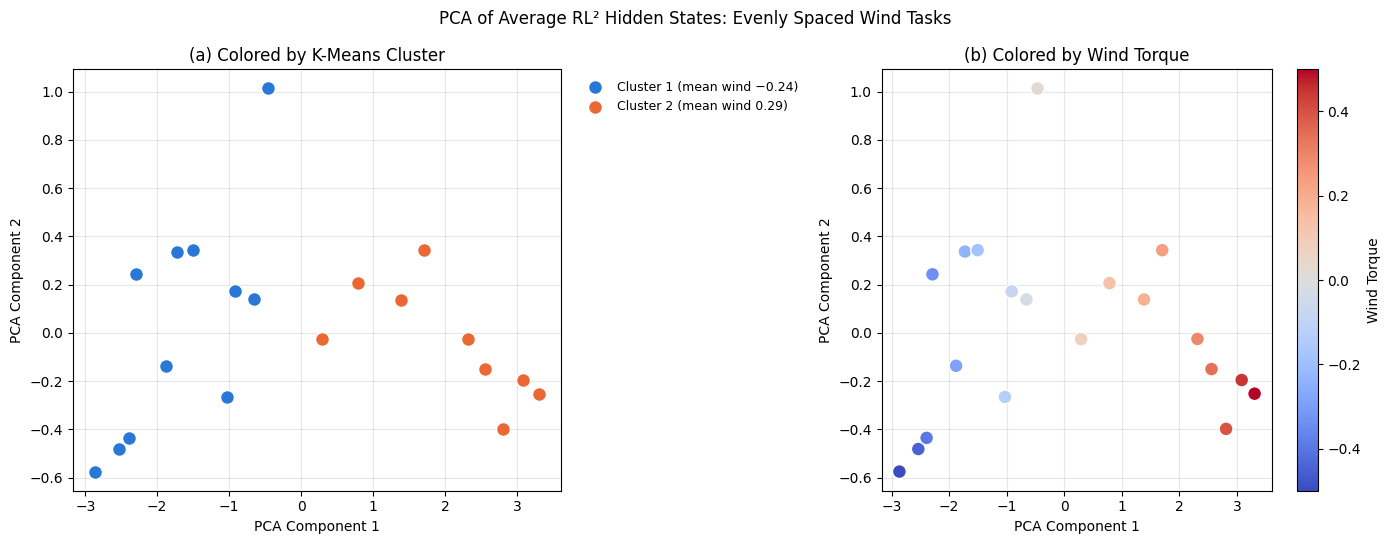

In [9]:
# Extract the wind torque of each task
reference_wind_values = task_parameters(system, env_configs)

# Cluster colors and numbering from kmeans_utils.py, the same in all notebooks

num_clusters = kmeans.n_clusters
assert num_clusters <= len(CLUSTER_COLORS), "Add more cluster colors for this number of clusters"

# Mean wind of every cluster, clusters numbered by it (1 = most negative wind)
cluster_wind_means, cluster_order, cluster_number = sort_clusters_by_task_parameter(
    kmeans.labels_, reference_wind_values, num_clusters
)

plot_name = "pendulum_kmeans_pca_reference.png"
save_path = os.path.join("diagrams", plot_name)
os.makedirs(os.path.dirname(save_path), exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# (a) Hidden states colored by their K-Means cluster, one scatter per cluster for the legend
for cluster in cluster_order:
    number = cluster_number[cluster]
    in_cluster = cluster_assignments == cluster
    axes[0].scatter(
        reduced_h[in_cluster, 0],
        reduced_h[in_cluster, 1],
        color=CLUSTER_COLORS[number - 1],
        s=100, edgecolors="white", linewidths=1,
        label=f"Cluster {number} (mean wind {cluster_wind_means[cluster]:.2f})".replace("-", "−")
    )
axes[0].legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False, fontsize=9)
axes[0].set_title("(a) Colored by K-Means Cluster")

# (b) Hidden states colored by their wind torque
# Fixed color range (-0.5 to +0.5), so all wind plots use the same scale
scatter = axes[1].scatter(
    reduced_h[:, 0],
    reduced_h[:, 1],
    c=reference_wind_values,
    cmap="coolwarm",
    vmin=-0.5, vmax=0.5,
    s=100, edgecolors="white", linewidths=1
)
fig.colorbar(scatter, ax=axes[1], label="Wind Torque")
axes[1].set_title("(b) Colored by Wind Torque")

for ax in axes:
    ax.set_xlabel("PCA Component 1")
    ax.set_ylabel("PCA Component 2")
    ax.grid(alpha=0.3)
    ax.set_axisbelow(True)

fig.suptitle("PCA of Average RL² Hidden States: Evenly Spaced Wind Tasks")
fig.tight_layout()
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()